# Rossmann Store Sales: Modelling (Task 2.1 - 2.5)
Preprocessing, sklearn pipeline with a Random Forest, loss-function choice, feature importance, confidence intervals and model serialization.

**Approach**
- Train only on **open days** (closed days are always 0 sales; the model predicts 0 when `Open == 0`).
- Target = `log1p(Sales)` (justified in section 3).
- Validation = **last 6 weeks of train** (same horizon as the real forecast), never a random split.

## 1. Setup and time-based split

In [1]:
import os, sys, time, warnings; sys.path.insert(0, ".."); os.chdir("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.logger import get_logger
from src.modeling import *
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
log = get_logger("rossmann.model.nb")
import joblib; from pathlib import Path; Path("cache").mkdir(exist_ok=True)
def cached(name, fn):
    """Heavy steps are cached in cache/ so the notebook re-runs quickly (delete cache/ to recompute)."""
    p = Path("cache") / f"{name}.pkl"
    if p.exists(): return joblib.load(p)
    r = fn(); joblib.dump(r, p, compress=3); return r
def save(name): plt.tight_layout(); plt.savefig(f"figures/{name}.png", bbox_inches="tight"); plt.show()

import gc
keep_tr = FEATURES + ["Sales", "Date", "Open"]; keep_te = FEATURES + ["Id", "Date", "Open"]
train_all = pd.read_pickle("data/processed/train_features.pkl")[keep_tr]; test = pd.read_pickle("data/processed/test_features.pkl")[keep_te]
train = train_all[train_all.Open == 1].reset_index(drop=True)          # open days only
f32 = [c for c in train.columns if train[c].dtype == "float64" and c != "Sales"]; train[f32] = train[f32].astype("float32"); test[f32] = test[f32].astype("float32")
del train_all; gc.collect()
fit_df, val_df = time_split(train, weeks=6)
y_fit, y_val = np.log1p(fit_df.Sales), np.log1p(val_df.Sales)
print(f"fit: {len(fit_df):,} rows up to {fit_df.Date.max().date()} | validation: {len(val_df):,} rows {val_df.Date.min().date()} → {val_df.Date.max().date()}")
print(len(FEATURES), "input features:", FEATURES)

fit: 804,056 rows up to 2015-06-19 | validation: 40,282 rows 2015-06-20 → 2015-07-31
24 input features: ['DayOfWeek', 'Promo', 'SchoolHoliday', 'CompetitionDistance', 'CompetitionOpenMonths', 'CompetitorOpenedInWindow', 'Promo2', 'Promo2Active', 'Promo2Months', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'MonthPart', 'IsMonthStart', 'IsMonthEnd', 'IsPayday', 'DaysToHoliday', 'DaysAfterHoliday', 'Store', 'StateHoliday', 'StoreType', 'Assortment']


**Preprocessing (Task 2.1)** is done in `src/features.py` (date, holiday-distance, month-position, payday, competition and Promo2 features) and inside the sklearn `Pipeline`: a `StoreEncoder` (store mean log-sales learned from the training fold only), `StandardScaler` for numeric columns and `OneHotEncoder` for `StateHoliday`, `StoreType`, `Assortment`.

## 2. Baselines (so we know what the model must beat)

In [2]:
def report(name, p):
    return {"model": name, "RMSPE": rmspe(val_df.Sales, p), "MAPE": mape(val_df.Sales, p), "MAE": mae(val_df.Sales, p)}
res = []
store_mean = fit_df.groupby("Store").Sales.mean(); res.append(report("Store mean", val_df.Store.map(store_mean).fillna(fit_df.Sales.mean())))
key = ["Store","DayOfWeek","Promo"]; med = fit_df.groupby(key).Sales.median().rename("p")
res.append(report("Store x weekday x promo median", val_df.join(med, on=key).p.fillna(val_df.Store.map(store_mean))))
pd.DataFrame(res).round(4)

,model,RMSPE,MAPE,MAE
0,Store mean,0.3305,0.2309,1456.5092
1,Store x weekday x promo median,0.1449,0.1080,765.6051


## 3. Choosing the loss function (Task 2.3)
I evaluate with **RMSPE** (root mean squared *percentage* error) and train on `log1p(Sales)`.

**Why:** (1) Sales range from a few hundred to 40k across stores, so an absolute error of 700 is huge for a small store and trivial for a big one. A percentage error treats all stores fairly, which matches how finance compares stores. (2) Squared error on the log target is approximately the squared *relative* error, so training on `log1p` optimises what we evaluate. (3) It is easy to explain: *"on average we are off by about X% of a store's daily sales"*. MAPE and MAE are reported alongside as more interpretable checks.

Quick evidence: the same small forest trained on raw sales vs log sales:

In [3]:
def loss_compare():
    kw = dict(n_estimators=30, max_samples=0.2, min_samples_leaf=3); out = []
    for name, target, inv in [("raw Sales target", fit_df.Sales, lambda z: z), ("log1p(Sales) target", y_fit, np.expm1)]:
        t0 = time.time(); m = build_pipeline(**kw).fit(fit_df[FEATURES], target); p = inv(m.predict(val_df[FEATURES]))
        out.append({**report(name, p), "seconds": round(time.time()-t0)}); del m; gc.collect()
    return out
out = cached("loss_compare", loss_compare)
pd.DataFrame(out).round(4)

,model,RMSPE,MAPE,MAE,seconds
0,raw Sales target,0.133,0.0975,670.3299,25
1,log1p(Sales) target,0.130,0.0969,679.7734,23


**Insight:** The baseline matters: a simple *store × weekday × promo median* already reaches RMSPE 0.145 (MAPE 10.8%), far better than a plain store mean (0.331), so the model has to beat 0.145 to add value. On the loss function, the log and raw targets are close: the log target gives a slightly lower RMSPE (0.130 vs 0.133) and MAPE, while the raw target has a slightly lower MAE (670 vs 680). A Random Forest is not very sensitive to the target scale, so I keep RMSPE as the evaluation metric (it matches the business need of comparing stores of very different size) and the log target as the default, but the gain here is small. The log target matters more for models sensitive to scale, such as the LSTM.

## 4. Random Forest in an sklearn Pipeline: small hyperparameter comparison (Task 2.2)

In [4]:
grid = [dict(n_estimators=60, max_samples=0.2, min_samples_leaf=5, max_features=0.5),
        dict(n_estimators=60, max_samples=0.2, min_samples_leaf=8, max_features=0.5),
        dict(n_estimators=60, max_samples=0.2, min_samples_leaf=5, max_features=0.33)]
# (min_samples_leaf=1 scored slightly better in a pre-test, RMSPE 0.127 vs 0.129, but made a ~400 MB model that is too big to deploy; leaf>=5 keeps the model small)
def run_grid():
    rows = []
    for kw in grid:
        t0 = time.time(); m = build_pipeline(**kw).fit(fit_df[FEATURES], y_fit); p = predict_sales(m, val_df, val_df.Open)
        rows.append({**kw, **{k: v for k, v in report("", p).items() if k != "model"}, "seconds": round(time.time()-t0)}); log.info("grid %s -> %s", kw, rows[-1]["RMSPE"]); del m; gc.collect()
    return rows
rows = cached("grid", run_grid)
grid_df = pd.DataFrame(rows).round(4); grid_df

,n_estimators,max_samples,min_samples_leaf,max_features,RMSPE,MAPE,MAE,seconds
0,60,0.2,5,0.50,0.1319,0.0983,687.9777,43
1,60,0.2,8,0.50,0.1341,0.1001,701.0324,42
2,60,0.2,5,0.33,0.1353,0.1008,704.9873,30


In [5]:
best_kw = grid[int(grid_df.RMSPE.idxmin())]; print("Best config:", best_kw)
best_kw = {**best_kw, "n_estimators": 60}
pipe = cached("rf_val", lambda: build_pipeline(**best_kw).fit(fit_df[FEATURES], y_fit))
pred = predict_sales(pipe, val_df, val_df.Open)
final = pd.DataFrame(res + [report("Random Forest (pipeline)", pred)]).round(4); final

Best config: {'n_estimators': 60, 'max_samples': 0.2, 'min_samples_leaf': 5, 'max_features': 0.5}


,model,RMSPE,MAPE,MAE
0,Store mean,0.3305,0.2309,1456.5092
1,Store x weekday x promo median,0.1449,0.1080,765.6051
2,Random Forest (pipeline),0.1319,0.0983,687.9777


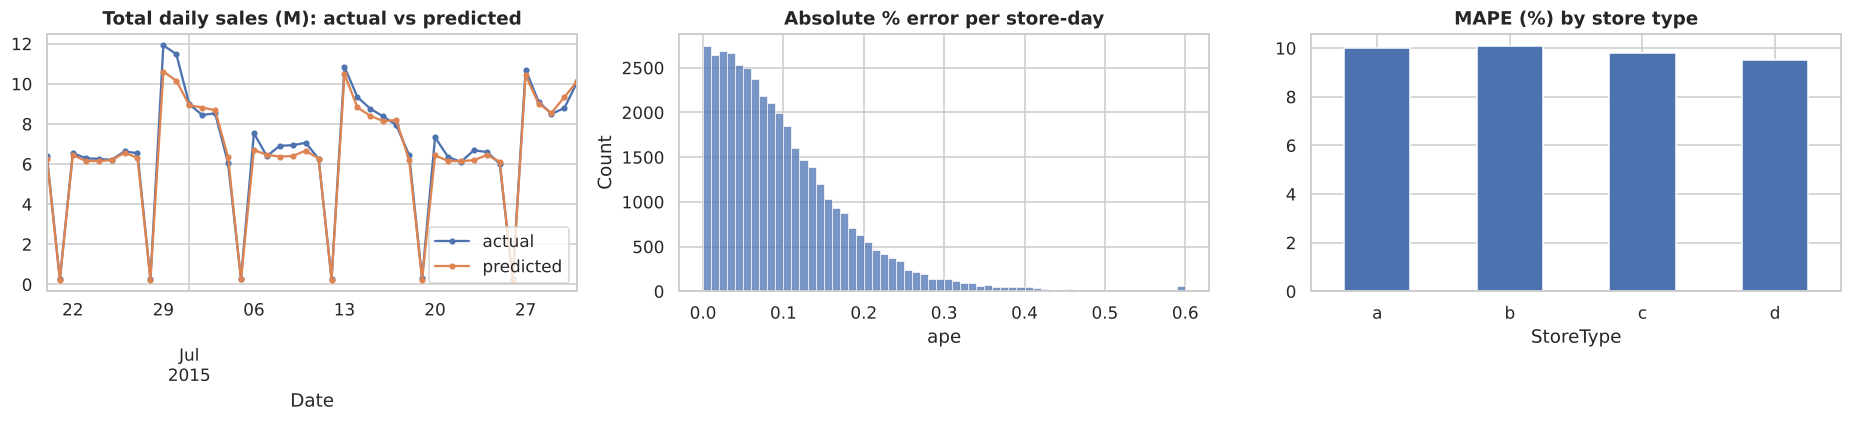

MAPE by promo: {0: 9.6, 1: 10.2} | by weekday: {1: 10.6, 2: 9.4, 3: 9.1, 4: 9.7, 5: 9.3, 6: 10.6, 7: 15.7}
Worst 5 stores (MAPE %): {292: 56.9, 909: 51.7, 876: 32.1, 192: 31.6, 770: 30.3}


In [6]:
v = val_df.assign(pred=pred, ape=np.abs(val_df.Sales - pred) / val_df.Sales)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
d = v.groupby("Date")[["Sales","pred"]].sum() / 1e6; d.plot(ax=ax[0], marker="o", ms=3); ax[0].set_title("Total daily sales (M): actual vs predicted"); ax[0].legend(["actual","predicted"])
sns.histplot(v.ape.clip(upper=.6), bins=60, ax=ax[1]); ax[1].set_title("Absolute % error per store-day")
v.groupby("StoreType").ape.mean().mul(100).plot(kind="bar", ax=ax[2], rot=0); ax[2].set_title("MAPE (%) by store type")
save("20_validation_fit"); print("MAPE by promo:", (v.groupby("Promo").ape.mean()*100).round(1).to_dict(), "| by weekday:", (v.groupby("DayOfWeek").ape.mean()*100).round(1).to_dict())
print("Worst 5 stores (MAPE %):", (v.groupby("Store").ape.mean().nlargest(5)*100).round(1).to_dict())

**Insight:** Among the three settings tried, `min_samples_leaf=5` with `max_features=0.5` was best (RMSPE 0.132). The final forest reaches **RMSPE 0.132, MAPE 9.8%, MAE ≈ 688**, about 9% better in RMSPE and 10% better in MAE than the strong store × weekday × promo baseline, so the model adds a real but modest improvement. (In a pre-test, `min_samples_leaf=1` scored ≈ 0.127 but produced a ≈ 400 MB model; I chose the ≈ 65 MB version so it can be deployed.) Errors are lowest midweek (≈ 9%), higher on Mondays and Saturdays (≈ 10.6%) and **highest on Sundays (≈ 15.7%)**, when only a few atypical stores are open. Promo days are slightly harder (10.2% vs 9.6%). A few stores are very hard to predict (e.g. 292 and 909 with MAPE > 50%), so they deserve store-specific attention.

## 5. Post-prediction analysis: feature importance (Task 2.4)

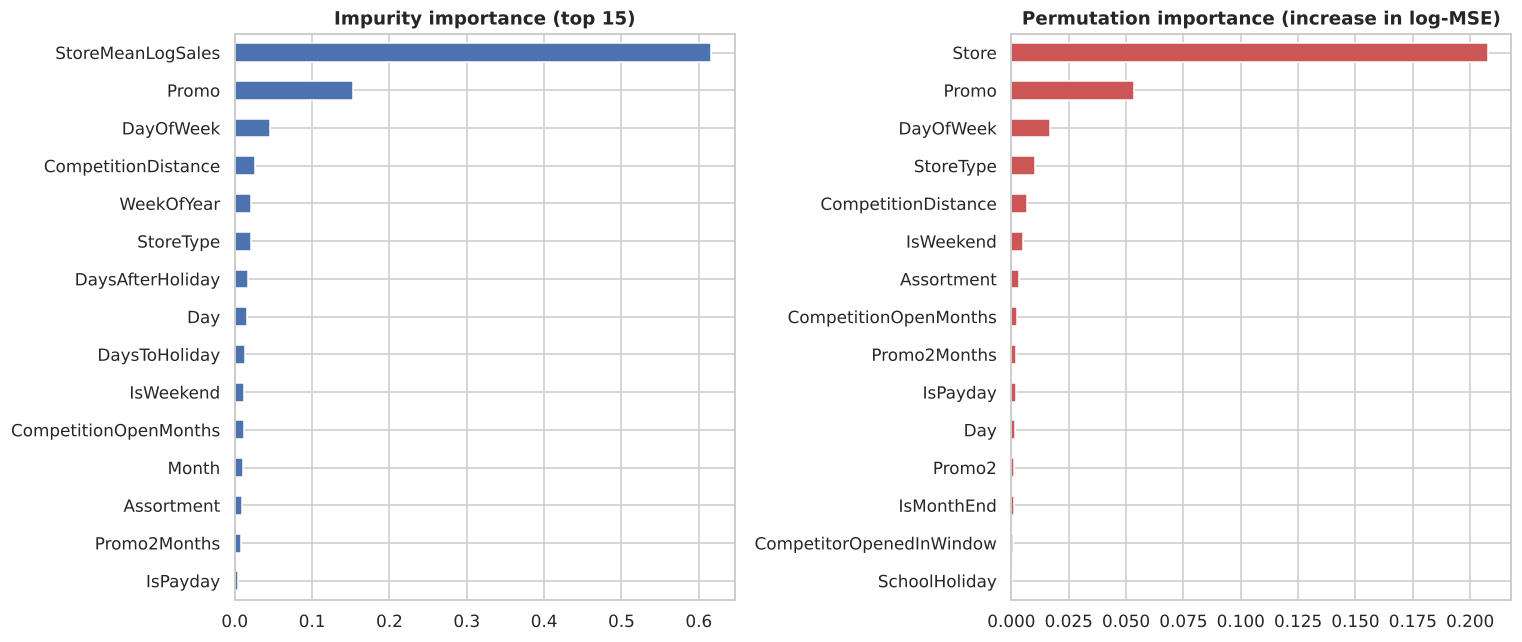

Impurity top: {'StoreMeanLogSales': 0.616, 'Promo': 0.152, 'DayOfWeek': 0.045, 'CompetitionDistance': 0.027, 'WeekOfYear': 0.021, 'StoreType': 0.02, 'DaysAfterHoliday': 0.017, 'Day': 0.015}
Permutation top: {'Store': 0.208, 'Promo': 0.054, 'DayOfWeek': 0.017, 'StoreType': 0.01, 'CompetitionDistance': 0.007, 'IsWeekend': 0.005, 'Assortment': 0.003, 'CompetitionOpenMonths': 0.002}


In [7]:
from sklearn.inspection import permutation_importance
names = pipe[:-1].get_feature_names_out(); imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=[n.split("__")[-1] for n in names])
imp_cat = imp.groupby(lambda n: next((c for c in CATEGORICAL if n.startswith(c)), n)).sum().sort_values()     # sum one-hot columns back
smp = val_df.sample(8000, random_state=0)
pi_mean = cached("perm", lambda: permutation_importance(pipe, smp[FEATURES], np.log1p(smp.Sales), scoring="neg_mean_squared_error", n_repeats=3, random_state=0, n_jobs=1).importances_mean)
pi_s = pd.Series(pi_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 6)); imp_cat.tail(15).plot(kind="barh", ax=ax[0]); ax[0].set_title("Impurity importance (top 15)")
pi_s.tail(15).plot(kind="barh", ax=ax[1], color="#c55"); ax[1].set_title("Permutation importance (increase in log-MSE)")
save("21_feature_importance"); print("Impurity top:", imp_cat.tail(8).round(3)[::-1].to_dict()); print("Permutation top:", pi_s.tail(8).round(3)[::-1].to_dict())

**Insight:** **Store identity dominates**: the store's own typical sales level (impurity importance 0.62; permutation importance of `Store` is the largest by far). After that, the main drivers within a store are **Promo**, **DayOfWeek**, then StoreType and CompetitionDistance. Holiday-distance and month-position features contribute little individually. This agrees with the EDA, where promo and weekday were the strongest within-store effects. Caveat: impurity importance favours continuous or high-cardinality features, so the permutation ranking is the more reliable one, and correlated features share importance.

## 6. Confidence intervals for predictions
Two approaches, compared on **held-out** data:
1. **Tree spread:** the 2.5% / 97.5% quantiles of the individual trees' predictions.
2. **Residual-calibrated band:** the 2.5% / 97.5% quantiles of log-residuals measured on the first 3 validation weeks, applied multiplicatively to predictions. Coverage is then checked on the last 3 weeks the band has not seen.

                   method  coverage  avg relative width
        Tree spread (95%)     0.851               0.398
Residual-calibrated (95%)     0.951               0.519
Residual band in % terms: -21.3% / +30.6%


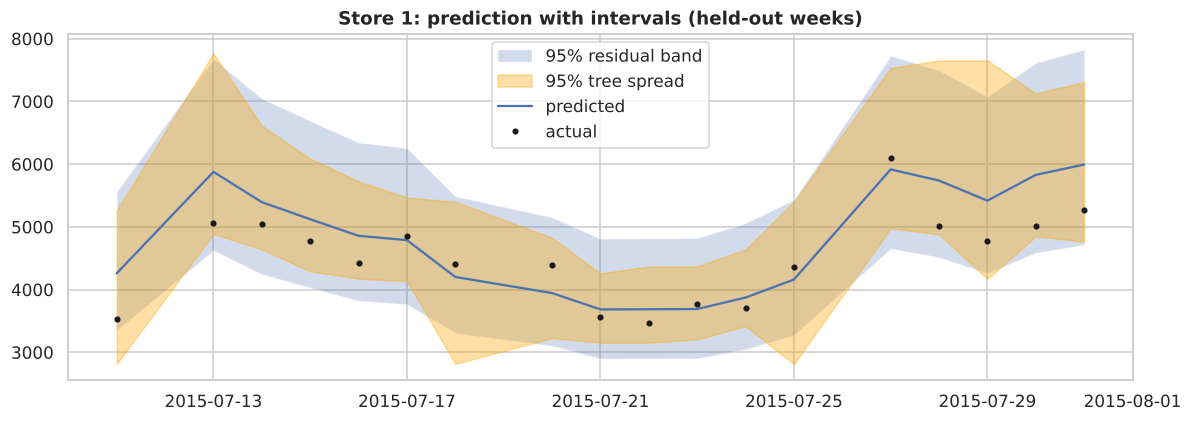

In [8]:
cut = val_df.Date.min() + pd.Timedelta(weeks=3); calib, hold = val_df[val_df.Date < cut], val_df[val_df.Date >= cut]
tp = tree_predictions(pipe, hold); lo1, hi1 = np.expm1(np.quantile(tp, .025, axis=0)), np.expm1(np.quantile(tp, .975, axis=0))
cov1 = np.mean((hold.Sales >= lo1) & (hold.Sales <= hi1)); w1 = np.mean((hi1 - lo1) / np.expm1(tp.mean(0)))
rl, rh = residual_interval(pipe, calib, np.log1p(calib.Sales)); mid = pipe.predict(hold[FEATURES])
lo2, hi2 = np.expm1(mid + rl), np.expm1(mid + rh); cov2 = np.mean((hold.Sales >= lo2) & (hold.Sales <= hi2)); w2 = np.mean((hi2 - lo2) / np.expm1(mid))
print(pd.DataFrame({"method": ["Tree spread (95%)", "Residual-calibrated (95%)"], "coverage": [cov1, cov2], "avg relative width": [w1, w2]}).round(3).to_string(index=False))
print(f"Residual band in % terms: {np.expm1(rl)*100:+.1f}% / {np.expm1(rh)*100:+.1f}%")
sid = hold.Store.iloc[0]; k = (hold.Store == sid).values
s = hold[k].assign(m=np.expm1(mid[k]), lo=lo2[k], hi=hi2[k], lo1=lo1[k], hi1=hi1[k]).sort_values("Date")
fig, ax = plt.subplots(figsize=(11, 4)); ax.fill_between(s.Date, s.lo, s.hi, alpha=.25, label="95% residual band"); ax.fill_between(s.Date, s.lo1, s.hi1, alpha=.35, color="orange", label="95% tree spread")
ax.plot(s.Date, s.m, label="predicted"); ax.plot(s.Date, s.Sales, "k.", label="actual"); ax.legend(); ax.set_title(f"Store {int(sid)}: prediction with intervals (held-out weeks)"); save("22_confidence_interval")

**Insight:** The **tree-spread interval is too narrow**: its nominal 95% band covers only **85%** of held-out store-days, because disagreement between trees measures model variance, not day-to-day noise. The **residual-calibrated band covers 95.1%** on weeks it had not seen, at a relative width of about 52% (roughly **-21% / +31%** around the prediction). I use this band in the test predictions (`Sales_lower` / `Sales_upper`) and will use it in the web app. Limitation: the same relative band is applied to every store and day, although uncertainty is higher on Sundays and for erratic stores. Calibrating it by store type or weekday would tighten it.

## 7. Final model, serialization and test predictions (Task 2.5)
Retrain on **all** training data with the chosen settings, save with a timestamped filename, and predict the 6-week test period. Closed days (`Open == 0`) are predicted as 0.

In [9]:
del pipe; gc.collect()
final_pipe = cached("rf_final", lambda: build_pipeline(**best_kw).fit(train[FEATURES], np.log1p(train.Sales)))
path = save_model(final_pipe); print("Saved:", path)
mid_t = final_pipe.predict(test[FEATURES]); del final_pipe; gc.collect(); open_t = test.Open.values == 1
out = test[["Id", "Store", "Date", "Open", "Promo"]].copy()
out["Sales"] = np.where(open_t, np.expm1(mid_t), 0.0)
out["Sales_lower"] = np.where(open_t, np.expm1(mid_t + rl), 0.0); out["Sales_upper"] = np.where(open_t, np.expm1(mid_t + rh), 0.0)
out.round(2).to_csv("data/test_predictions.csv", index=False); print(out.shape, "| test open rows:", open_t.sum()); out.head()

2026-11-14 09:27:05,896 | INFO | rossmann.model | Saved model to models/rf-14-11-2026-09-27-02-00.pkl


Saved: models/rf-14-11-2026-09-27-02-00.pkl


(41088, 8) | test open rows: 35104


,Id,Store,Date,Open,Promo,Sales,Sales_lower,Sales_upper
0,1,1,2015-09-17,1,1,4767.508985,3751.576936,6227.937570
1,2,3,2015-09-17,1,1,7678.106207,6042.070681,10029.949570
2,3,7,2015-09-17,1,1,9175.777916,7220.663053,11986.306076
3,4,8,2015-09-17,1,1,6162.373804,4849.265452,8050.001008
4,5,9,2015-09-17,1,1,6984.924723,5496.571689,9124.470688


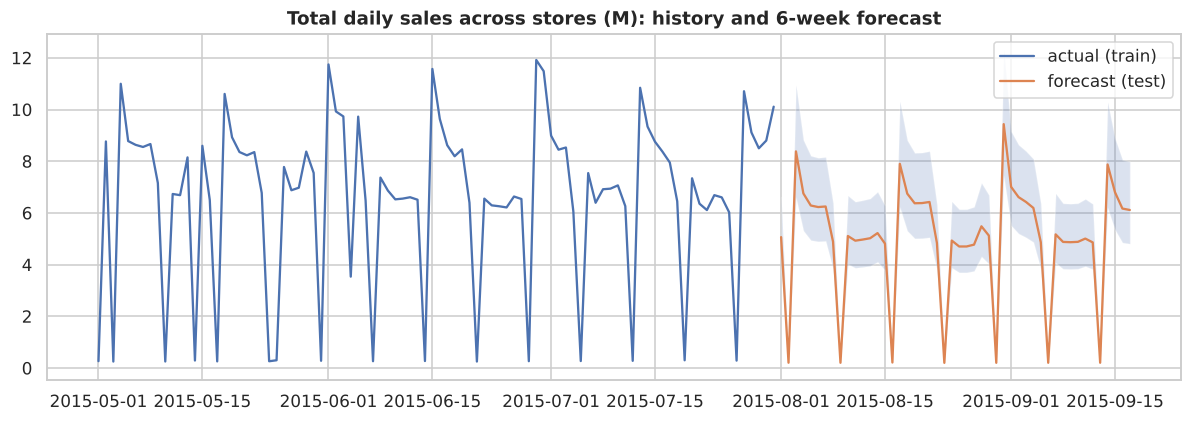

Reload check: True


In [10]:
daily = out.groupby("Date")[["Sales","Sales_lower","Sales_upper"]].sum() / 1e6
hist = train.groupby("Date").Sales.sum().loc["2015-05-01":] / 1e6
fig, ax = plt.subplots(figsize=(11, 4)); ax.plot(hist.index, hist.values, label="actual (train)"); ax.plot(daily.index, daily.Sales, label="forecast (test)"); ax.fill_between(daily.index, daily.Sales_lower, daily.Sales_upper, alpha=.2)
ax.set_title("Total daily sales across stores (M): history and 6-week forecast"); ax.legend(); save("23_test_forecast")
del smp; gc.collect(); reloaded = joblib.load(path); print("Reload check:", np.allclose(reloaded.predict(test[FEATURES].head(500)), mid_t[:500]))

## Summary

**Results**
- Random Forest in an sklearn `Pipeline` (store encoder, scaler, one-hot, forest): **RMSPE 0.132 / MAPE 9.8%** on the last 6 weeks of train, compared with 0.145 for a strong weekday/promo baseline.
- Store level, Promo and DayOfWeek drive predictions; a 95% residual-calibrated interval has verified coverage of 95%.
- Model saved as a timestamped file in `models/` (≈ 65 MB, reload-tested). Test predictions with lower/upper bounds are in `data/test_predictions.csv`.

**Limits and next steps**
- Improvement over the baseline is modest; adding store × weekday × promo history encodings, lag/rolling features or gradient boosting would likely help.
- The app also needs customer numbers, so a second model for `Customers` is required.
- Next: LSTM (Task 2.6), MLflow tracking and serving (2.7), web app (Task 3).